In [37]:
#!/usr/bin/env python3

import os, sys,glob
sys.path.append('../')
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
from collections import namedtuple
import pandas as pd
from helper import getModelDict
from triggers_helper import in_N,in_Np1,in_ms,in_hcal,selectionOnTime,selectionDelayed
try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass
delphesDir = os.path.abspath("../../DelphesLLP")
os.environ['ROOT_INCLUDE_PATH'] = os.path.join(delphesDir,"external")

import ROOT


ROOT.gSystem.Load(os.path.join(delphesDir,"libDelphes.so"))

ROOT.gInterpreter.Declare('#include "classes/SortableObject.h"')
ROOT.gInterpreter.Declare('#include "classes/DelphesClasses.h"')
ROOT.gInterpreter.Declare('#include "external/ExRootAnalysis/ExRootTreeReader.h"')



True

In [38]:
def get_labels(df_selected,all_df=[],full_label=False):

    labels = {'mS' : lambda x: r'$m_S$ =' + f' {x:1.2f} [GeV]',
          'm1' : lambda x: r'$m_{\chi_1}$ =' + f' {x:1.2f} [GeV]',
          'dm' : lambda x: r'$\Delta m$ =' + f' {x:1.2f} [GeV]',
          'tau' : lambda x: r'$c \tau$ =' + f' {x*3e8:1.0f} [m]',
        #   'm0' : lambda x: r'$m_{\chi_0}$ =' + f' {x:1.2f} [GeV]',
        #   'm2' : lambda x: r'$m_{\chi_2}$ =' + f' {x:1.2f} [GeV]'          
         }

    model_label = [labels[k](float(df_selected[k].values[0])) for k in labels if k in df_selected.columns]
    if full_label:
        return ', '.join(model_label)
    all_labels = []
    for df in all_df:
        all_labels.append([labels[k](float(df[k].values[0])) for k in labels if k in df.columns])
    labelsDict = {}
    for labelList in all_labels:
        for label in labelList:
            labelsDict.setdefault(label,0)
            labelsDict[label] += 1
    common_labels = [l for l,c in labelsDict.items() if c == len(all_labels)]
    short_label = [l for l in model_label if l not in common_labels]
    short_label = ', '.join(short_label)
    common_label = ', '.join(common_labels)
    return short_label,common_label


def closestDF(dfList, point, relative=True):
    """Return the DataFrame with the parameters closest to point 
    (dict column -> value)."""
    min_dist = float('inf')
    closest_df = None
    for df in dfList:
        row = df.iloc[0]
        cols = list(point.keys())
        target = pd.Series(point)
        diff = row[cols] - target
        if relative:
            diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
        dist = sum(diff**2)
        if dist < min_dist:
            min_dist = dist
            closest_df = df
    return closest_df   # double brackets keep it a DataFrame


## Read events

In [39]:
processFolders = '../../processFolders/test_finalState'


runs = ['run_01']

files = []
for f in runs:
    runFolder = os.path.join(processFolders, 'Events', f)
    rootFile = list(glob.glob(os.path.join(runFolder, '*.root')))[0]
    files.append(rootFile)

c_light = 2.99792458e8

### Get Event information

In [40]:
def get_ROI(finalStates,pTbins = [0.0,4.0,6.0,8.0,10.0,12.0,15.0,20.0,1e5], pdgInvisible=4000022):

    tracks = []
    for ptc in finalStates:
        if ptc.PT < min(pTbins):
            continue
        if ptc.Charge == 0:
            continue
        if abs(ptc.PID) == pdgInvisible:
            continue
        tracks.append(ptc)
    tracks = sorted(tracks, key=lambda x: x.PT, reverse=True)
    roi = np.histogram([t.PT for t in tracks], bins=pTbins)[0]

    roiDict = {f'MU_{pt:1.1f}': roi[i] for i,pt in enumerate(pTbins[:-1])}
    return roiDict

In [41]:
dfList = []
for file in files:
    if not os.path.isfile(file):
        print(f"File {file} not found, skipping")
        continue
    f = ROOT.TFile(file,'read')
    tree = f.Get("Delphes")
    nevts = tree.GetEntries()
    modelData = getModelDict(file,verbose=False)
    modelData['dm'] = modelData['m1'] - modelData['m0']
    modelData['ctau'] = modelData['tau']*c_light
    roiDictList = []
    for ievt in range(nevts):
        tree.GetEntry(ievt)

        metOnTime = tree.L1METOnTime.At(0)
        jetsOnTime = list(tree.HLTJetOnTime)
        evt_cutFlow = selectionOnTime(metOnTime,jetsOnTime)
         ### Selection (delayed, N+1)
        llp_decays = list(tree.llpDirectDaughters)
        evt_cutFlow.update(selectionDelayed(llp_decays))
        # If any of the cuts failed, stop
        if any(val == 0 for val in evt_cutFlow.values()):
            passed = False
        else:
            passed = True

        roiDict = get_ROI(tree.llpFinalDaughters)
        roiDict['passed'] = passed
        roiDictList.append(roiDict)
        # if passed:
        #     print('\n',ievt)
        #     for key,val in roiDict.items():
        #         if val == 0:
        #             continue
        #         print(f"{key}: {val}")
        #     print('Direct daugthers')
        #     for d in tree.llpDirectDaughters:
        #         if abs(d.PID) == 4000022:
        #             continue
        #         print(d.PID,d.PT,d.E,d.E/4.0)
        #     print('Final daugthers')
        #     for d in tree.llpFinalDaughters:
        #         if abs(d.PID) == 4000022:
        #             continue
        #         print(d.PID,d.Charge,d.PT,d.E,d.E/4.0)
        #     break

    f.Close()
    df = pd.DataFrame(roiDictList)
    for k,v in modelData.items():
        df[k] = v
    dfList.append(df)


In [42]:
for df in dfList:
    print(f"{get_labels(df, full_label=True)}: {len(df)} events")

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 198.40 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m]: 25969 events


### Plot ROI distribution

In [43]:
df.columns

Index(['MU_0.0', 'MU_4.0', 'MU_6.0', 'MU_8.0', 'MU_10.0', 'MU_12.0', 'MU_15.0',
       'MU_20.0', 'passed', 'm1', 'm0', 'mS', 'tau', 'BRchi12bbchi0',
       'BRchi12tautauchi0', 'BRchi22bbchi0', 'BRchi22tautauchi0',
       'BRchi22tautauchi1', 'BRs2chi1chi2', 'BRs2WW', 'BRs2hh', 'BRs2ZZ',
       'BRs2tt', 'BRs2chi0chi2', 'BRs2gg', 'BRs2bb', 'BRs2tautau',
       'BRs2chi0chi1', 'm2', 'lambdauv', 'chxx10', 'ychi20', 'ychi21', 'sina',
       'xsec_pb', 'dm', 'ctau'],
      dtype='object')

In [44]:
df_filtered = dfList
common_label = get_labels(df_filtered[0], all_df=df_filtered, full_label=False)[1]

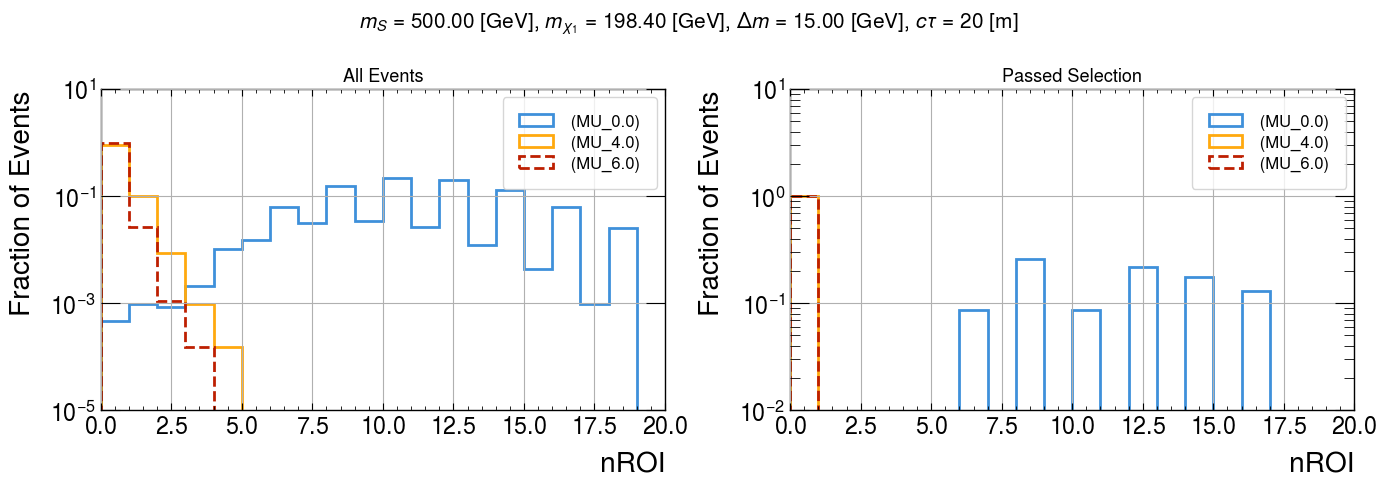

In [45]:
nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,passed in zip(axes,[False,True]):
    if passed:
        ax.set_title(fr'Passed Selection',fontsize=13)        
    else:
        ax.set_title(fr'All Events',fontsize=13)
    for df0 in df_filtered:
        if passed:
            df = df0[df0['passed']]
        else:
            df = df0
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['MU_0.0'],bins=np.arange(0.,20.0,1.0),
                     histtype='step',
                     weights=[1.0/len(df)]*len(df),
                     label=f'{short_label} (MU_0.0)',linewidth=2)
        ax.hist(df['MU_4.0'],bins=np.arange(0.,20.0,1.0),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label} (MU_4.0)',linewidth=2)
        ax.hist(df['MU_6.0'],bins=np.arange(0.,5.0,1.0),
                     histtype='step',linestyle='dashed',
                     weights=[1.0/len(df)]*len(df),
                     label=f'{short_label} (MU_6.0)',linewidth=2)
        ax.set_yscale('log')
        ax.set_xlabel(r'nROI')
        ax.set_ylabel('Fraction of Events')
        ax.legend(loc='upper right',framealpha=0.8,frameon=True,fontsize=12)
        # ax.set_ylim(1e-3,1.0)
        ax.grid()
plt.tight_layout()
plt.show()